# Machine Learning – Practical Session 3
### Hypothesis spaces, feature representations and model generalization

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import LeaveOneOut, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
pd.set_option("display.precision", 4)

In [3]:
data = {
    "Student": [f"S{i}" for i in range(1, 11)],
    "Study Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Exam Score":  [42, 48, 55, 59, 66, 70, 78, 81, 89, 91],
}
df = pd.DataFrame(data)
df

,Student,Study Hours,Exam Score
0,S1,1,42
1,S2,2,48
2,S3,3,55
3,S4,4,59
4,S5,5,66
5,S6,6,70
6,S7,7,78
7,S8,8,81
8,S9,9,89
9,S10,10,91


In [3]:
print("Dimensions (rows, columns):", df.shape)
print()
df.describe()

Dimensions (rows, columns): (10, 3)



,Study Hours,Exam Score
count,10.0000,10.0000
mean,5.5000,67.9000
std,3.0277,16.9079
min,1.0000,42.0000
25%,3.2500,56.0000
50%,5.5000,68.0000
75%,7.7500,80.2500
max,10.0000,91.0000


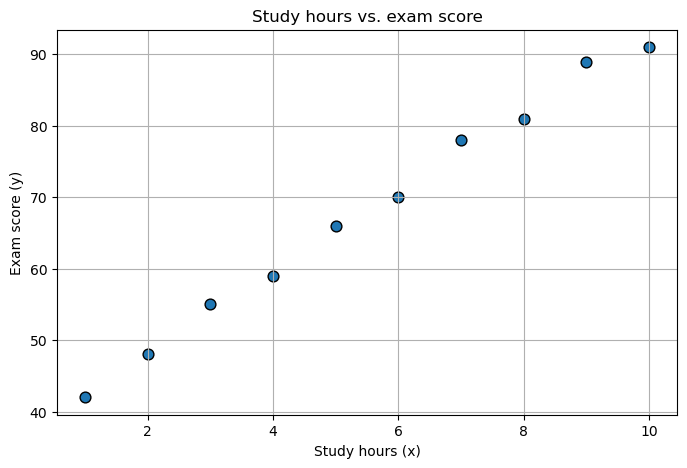

In [4]:
plt.scatter(df["Study Hours"], df["Exam Score"], color="tab:blue", s=60, edgecolor="k")
plt.xlabel("Study hours (x)")
plt.ylabel("Exam score (y)")
plt.title("Study hours vs. exam score")
plt.show()

**Observation:** the relationship is strongly increasing and very close to linear, with only small deviations. 

In [5]:
# Feature matrix (2-D, as required by scikit-learn) and target vector
X = df[["Study Hours"]].values          # shape (10, 1)
y = df["Exam Score"].values             # shape (10,)
print(X.shape, y.shape)

(10, 1) (10,)


In [6]:
models = {
    "Linear Regression": LinearRegression(),
    "Polynomial Regression (degree 2)": make_pipeline(PolynomialFeatures(degree=2, include_bias=False), LinearRegression()),
    "Polynomial Regression (degree 3)": make_pipeline(PolynomialFeatures(degree=3, include_bias=False), LinearRegression()),
    "Decision Tree (depth 1)": DecisionTreeRegressor(max_depth=1, random_state=0),
    "Decision Tree (depth 3)": DecisionTreeRegressor(max_depth=3, random_state=0),
    "KNN (k = 3)": KNeighborsRegressor(n_neighbors=3),
}

for name, model in models.items():
    model.fit(X, y)
    print(f"Fitted: {name}")

Fitted: Linear Regression
Fitted: Polynomial Regression (degree 2)
Fitted: Polynomial Regression (degree 3)
Fitted: Decision Tree (depth 1)
Fitted: Decision Tree (depth 3)
Fitted: KNN (k = 3)


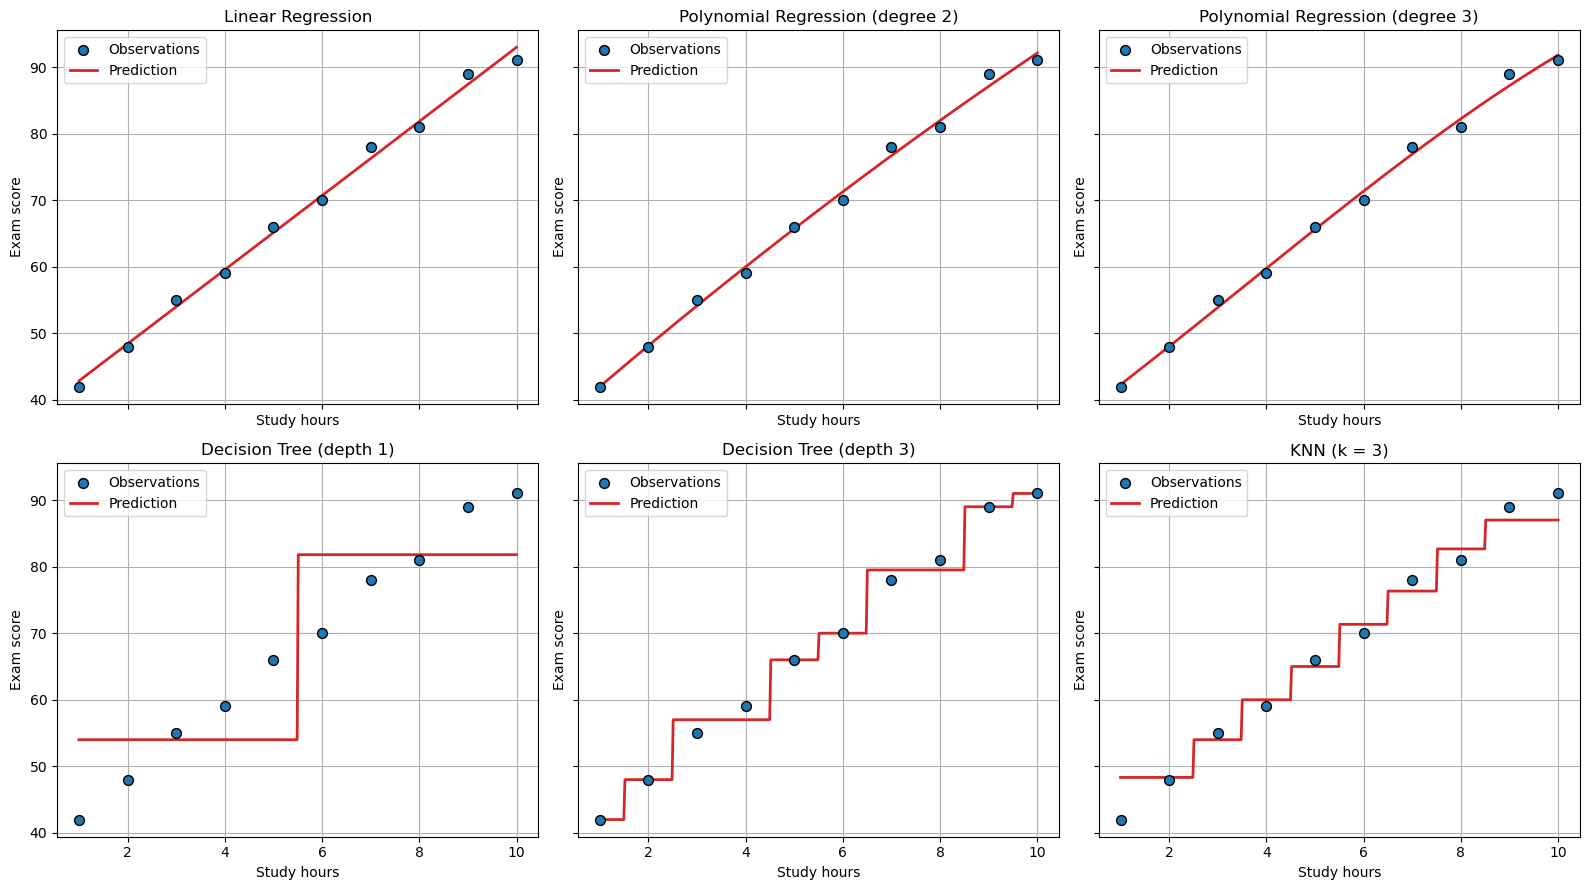

In [7]:
x_grid = np.linspace(1, 10, 400).reshape(-1, 1)

fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, sharey=True)
for ax, (name, model) in zip(axes.ravel(), models.items()):
    ax.scatter(X, y, color="tab:blue", edgecolor="k", s=50, label="Observations", zorder=3)
    ax.plot(x_grid, model.predict(x_grid), color="tab:red", lw=2, label="Prediction")
    ax.set_title(name)
    ax.set_xlabel("Study hours")
    ax.set_ylabel("Exam score")
    ax.legend()
plt.tight_layout()
plt.show()

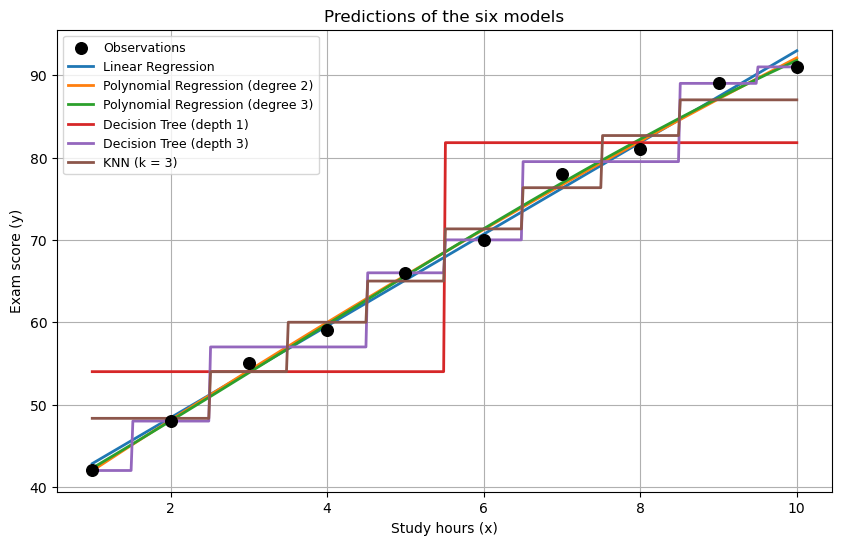

In [8]:
# All six models together on a single plot
plt.figure(figsize=(10, 6))
plt.scatter(X, y, color="black", s=70, zorder=5, label="Observations")
for name, model in models.items():
    plt.plot(x_grid, model.predict(x_grid), lw=2, label=name)
plt.xlabel("Study hours (x)")
plt.ylabel("Exam score (y)")
plt.title("Predictions of the six models")
plt.legend(fontsize=9)
plt.show()

In [9]:
rows = []
for name, model in models.items():
    pred = model.predict(X)
    rows.append({
        "Model": name,
        "Training RMSE": np.sqrt(mean_squared_error(y, pred)),
        "Training R²": r2_score(y, pred),
    })
results_A = pd.DataFrame(rows)
results_A

,Model,Training RMSE,Training R²
0,Linear Regression,1.1672,0.9947
1,Polynomial Regression (degree 2),1.0435,0.9958
2,Polynomial Regression (degree 3),1.0211,0.9959
3,Decision Tree (depth 1),8.0050,0.7509
4,Decision Tree (depth 3),1.1180,0.9951
5,KNN (k = 3),2.6562,0.9726


**Discussion:**
- *Linear regression* has a very restrictive hypothesis space (straight lines) but matches this almost-linear data well.
- *Polynomial regression* (degree 2, 3) enlarges the space to smooth curves, so training error can only decrease (the models are nested).
- *Decision trees* produce **piecewise-constant** (step) functions. Depth 1 gives only two plateaus (very coarse); depth 3 gives up to 8 steps and fits the training points much more closely.
- *KNN* also yields a piecewise-constant, local-average prediction and cannot extrapolate beyond the observed range.

Low training error alone says nothing about generalization – that is the purpose of Part B.

In [10]:
loo = LeaveOneOut()
print("Number of splits:", loo.get_n_splits(X))
print()

for i, (train_idx, test_idx) in enumerate(loo.split(X), start=1):
    print(f"Iteration {i:2d} | train (9 obs): {train_idx} | test (1 obs): {test_idx}")

Number of splits: 10

Iteration  1 | train (9 obs): [1 2 3 4 5 6 7 8 9] | test (1 obs): [0]
Iteration  2 | train (9 obs): [0 2 3 4 5 6 7 8 9] | test (1 obs): [1]
Iteration  3 | train (9 obs): [0 1 3 4 5 6 7 8 9] | test (1 obs): [2]
Iteration  4 | train (9 obs): [0 1 2 4 5 6 7 8 9] | test (1 obs): [3]
Iteration  5 | train (9 obs): [0 1 2 3 5 6 7 8 9] | test (1 obs): [4]
Iteration  6 | train (9 obs): [0 1 2 3 4 6 7 8 9] | test (1 obs): [5]
Iteration  7 | train (9 obs): [0 1 2 3 4 5 7 8 9] | test (1 obs): [6]
Iteration  8 | train (9 obs): [0 1 2 3 4 5 6 8 9] | test (1 obs): [7]
Iteration  9 | train (9 obs): [0 1 2 3 4 5 6 7 9] | test (1 obs): [8]
Iteration 10 | train (9 obs): [0 1 2 3 4 5 6 7 8] | test (1 obs): [9]


In [11]:
# Same splits shown with the actual data values
for i, (train_idx, test_idx) in enumerate(loo.split(X), start=1):
    print(f"--- Iteration {i} ---")
    print("  Train x:", X[train_idx].ravel().tolist())
    print("  Train y:", y[train_idx].tolist())
    print("  Test  x:", X[test_idx].ravel().tolist(), "| Test y:", y[test_idx].tolist())

--- Iteration 1 ---
  Train x: [2, 3, 4, 5, 6, 7, 8, 9, 10]
  Train y: [48, 55, 59, 66, 70, 78, 81, 89, 91]
  Test  x: [1] | Test y: [42]
--- Iteration 2 ---
  Train x: [1, 3, 4, 5, 6, 7, 8, 9, 10]
  Train y: [42, 55, 59, 66, 70, 78, 81, 89, 91]
  Test  x: [2] | Test y: [48]
--- Iteration 3 ---
  Train x: [1, 2, 4, 5, 6, 7, 8, 9, 10]
  Train y: [42, 48, 59, 66, 70, 78, 81, 89, 91]
  Test  x: [3] | Test y: [55]
--- Iteration 4 ---
  Train x: [1, 2, 3, 5, 6, 7, 8, 9, 10]
  Train y: [42, 48, 55, 66, 70, 78, 81, 89, 91]
  Test  x: [4] | Test y: [59]
--- Iteration 5 ---
  Train x: [1, 2, 3, 4, 6, 7, 8, 9, 10]
  Train y: [42, 48, 55, 59, 70, 78, 81, 89, 91]
  Test  x: [5] | Test y: [66]
--- Iteration 6 ---
  Train x: [1, 2, 3, 4, 5, 7, 8, 9, 10]
  Train y: [42, 48, 55, 59, 66, 78, 81, 89, 91]
  Test  x: [6] | Test y: [70]
--- Iteration 7 ---
  Train x: [1, 2, 3, 4, 5, 6, 8, 9, 10]
  Train y: [42, 48, 55, 59, 66, 70, 81, 89, 91]
  Test  x: [7] | Test y: [78]
--- Iteration 8 ---
  Train x: [1,

**Observation:** in each iteration exactly one student is held out for testing while the other nine are used for training. Over the 10 iterations every observation is used exactly once as test data.

In [12]:
def poly_lr(degree):
    # include_bias=False: LinearRegression already fits an intercept
    return make_pipeline(PolynomialFeatures(degree=degree, include_bias=False), LinearRegression())

def loocv_rmse(model, X, y):
    """LOOCV RMSE using cross_val_score + LeaveOneOut.
    Each fold has a single test point, so the fold MSE is a squared error;
    the LOOCV MSE is their mean, and RMSE = sqrt(MSE)."""
    scores = cross_val_score(model, X, y, cv=LeaveOneOut(), scoring="neg_mean_squared_error")
    return np.sqrt(-scores.mean())

def train_rmse(model, X, y):
    model.fit(X, y)
    return np.sqrt(mean_squared_error(y, model.predict(X)))

degrees = [1, 2, 3, 5, 9]
rows = []
for d in degrees:
    m = poly_lr(d)
    rows.append({
        "Polynomial Degree": d,
        "Training RMSE": train_rmse(m, X, y),
        "LOOCV RMSE": loocv_rmse(poly_lr(d), X, y),
    })
results_B = pd.DataFrame(rows)
results_B

,Polynomial Degree,Training RMSE,LOOCV RMSE
0,1,1.1672,1.5486
1,2,1.0435,1.5728
2,3,1.0211,2.0620
3,5,0.8943,3.7070
4,9,0.0002,261.9060


In [13]:
best = results_B.loc[results_B["LOOCV RMSE"].idxmin()]
print(f"Lowest LOOCV RMSE: degree {int(best['Polynomial Degree'])} "
      f"(LOOCV RMSE = {best['LOOCV RMSE']:.4f})")

Lowest LOOCV RMSE: degree 1 (LOOCV RMSE = 1.5486)


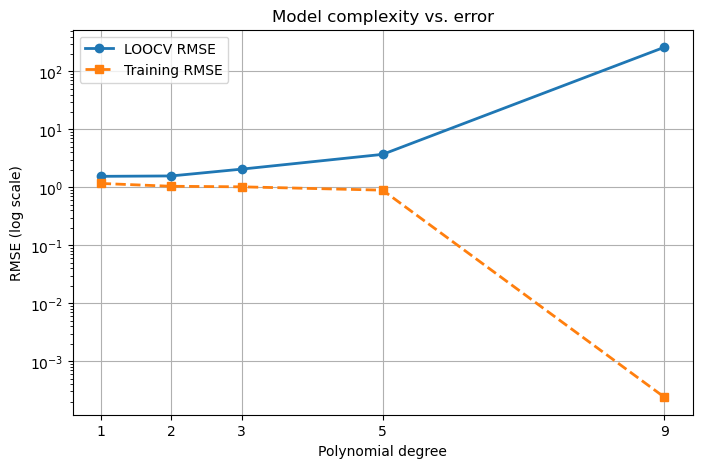

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(results_B["Polynomial Degree"], results_B["LOOCV RMSE"], "o-", lw=2, label="LOOCV RMSE")
plt.plot(results_B["Polynomial Degree"], results_B["Training RMSE"], "s--", lw=2, label="Training RMSE")
plt.yscale("log")
plt.xticks(degrees)
plt.xlabel("Polynomial degree")
plt.ylabel("RMSE (log scale)")
plt.title("Model complexity vs. error")
plt.legend()
plt.show()

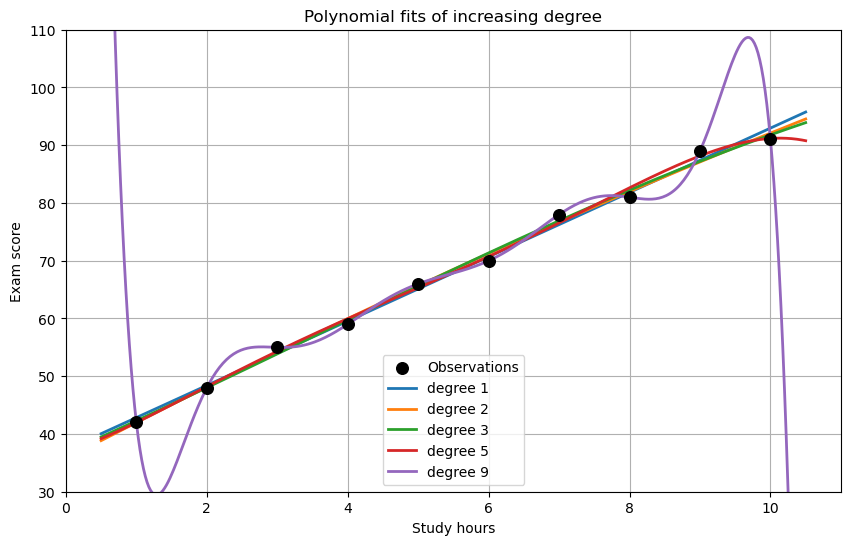

In [15]:
# Fitted curves for the five degrees
plt.figure(figsize=(10, 6))
plt.scatter(X, y, color="black", s=70, zorder=5, label="Observations")
x_ext = np.linspace(0.5, 10.5, 400).reshape(-1, 1)
for d in degrees:
    m = poly_lr(d).fit(X, y)
    plt.plot(x_ext, m.predict(x_ext), lw=2, label=f"degree {d}")
plt.ylim(30, 110)
plt.xlabel("Study hours")
plt.ylabel("Exam score")
plt.title("Polynomial fits of increasing degree")
plt.legend()
plt.show()

In [16]:
# Numerical check: degree 9 with standardized features (well-conditioned)
m9 = make_pipeline(PolynomialFeatures(degree=9, include_bias=False), StandardScaler(), LinearRegression())
print(f"Degree 9 + scaling | Training RMSE = {train_rmse(m9, X, y):.6f} | LOOCV RMSE = {loocv_rmse(m9, X, y):.4f}")

Degree 9 + scaling | Training RMSE = 0.000000 | LOOCV RMSE = 222.1629


**Discussion:**
- In theory, training RMSE is non-increasing with degree (nested hypothesis spaces) and reaches ~0 at degree 9, where the polynomial can interpolate all 10 points. In the table above the degree-9 training RMSE is **not** ~0: with unscaled features x⁹ reaches 10⁹, so the least-squares problem is extremely ill-conditioned and the solver cannot recover the exact interpolant. The next cell checks this with standardized features.
- LOOCV RMSE does **not** keep decreasing: past a certain degree it stops improving and then grows, especially at degree 9, where the model has as many parameters as observations (and, in each LOOCV fold, more parameters than training points). This is **overfitting**: a small training error does not guarantee small error on unseen data.
- Choose the degree with the lowest LOOCV RMSE, not the lowest training RMSE.

In [17]:
rep_models = {
    "Original: x":               LinearRegression(),
    "Polynomial: x, x², x³":     poly_lr(3),
    "Polynomial: x, ..., x⁵":    poly_lr(5),
}

rows = []
for name, m in rep_models.items():
    rows.append({"Representation": name, "LOOCV RMSE": loocv_rmse(m, X, y)})
pd.DataFrame(rows)

,Representation,LOOCV RMSE
0,Original: x,1.5486
1,"Polynomial: x, x², x³",2.0620
2,"Polynomial: x, ..., x⁵",3.7070


In [18]:
def reg_pipeline(reg_cls, degree, alpha):
    kwargs = {"max_iter": 100_000} if reg_cls is Lasso else {}
    return Pipeline([
        ("poly",   PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("reg",    reg_cls(alpha=alpha, **kwargs)),
    ])

alphas = [0.01, 0.1, 1, 10]
rows = []
for reg_cls, reg_name in [(Ridge, "Ridge (L2)"), (Lasso, "Lasso (L1)")]:
    for degree in [3, 5]:
        for alpha in alphas:
            rows.append({
                "Model": reg_name,
                "Degree": degree,
                "alpha": alpha,
                "LOOCV RMSE": loocv_rmse(reg_pipeline(reg_cls, degree, alpha), X, y),
            })
results_reg = pd.DataFrame(rows)
results_reg

,Model,Degree,alpha,LOOCV RMSE
0,Ridge (L2),3,0.01,1.7084
1,Ridge (L2),3,0.10,1.8425
2,Ridge (L2),3,1.00,3.7527
3,Ridge (L2),3,10.00,6.5027
4,Ridge (L2),5,0.01,2.1442
5,Ridge (L2),5,0.10,1.8071
6,Ridge (L2),5,1.00,3.5735
7,Ridge (L2),5,10.00,7.2820
8,Lasso (L1),3,0.01,1.5889
9,Lasso (L1),3,0.10,1.5869


Model,Lasso (L1),Ridge (L2)
alpha,,
0.01,1.7654,2.1442
0.10,1.6223,1.8071
1.00,1.9187,3.5735
10.00,11.8773,7.2820


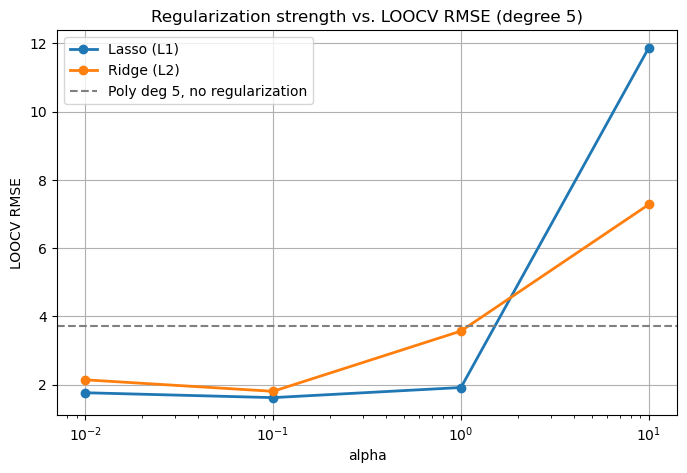

In [19]:
# Focus: degree-5 polynomial features
reg5 = results_reg[results_reg["Degree"] == 5].pivot(index="alpha", columns="Model", values="LOOCV RMSE")
display(reg5)

plt.figure(figsize=(8, 5))
for col in reg5.columns:
    plt.plot(reg5.index, reg5[col], "o-", lw=2, label=col)
plt.axhline(loocv_rmse(poly_lr(5), X, y), color="gray", ls="--", label="Poly deg 5, no regularization")
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("LOOCV RMSE")
plt.title("Regularization strength vs. LOOCV RMSE (degree 5)")
plt.legend()
plt.show()

In [20]:
# Best alpha for each regularized model at degree 5
best_ridge = results_reg[(results_reg.Model == "Ridge (L2)") & (results_reg.Degree == 5)].nsmallest(1, "LOOCV RMSE").iloc[0]
best_lasso = results_reg[(results_reg.Model == "Lasso (L1)") & (results_reg.Degree == 5)].nsmallest(1, "LOOCV RMSE").iloc[0]
print(f"Best Ridge (deg 5): alpha = {best_ridge['alpha']}, LOOCV RMSE = {best_ridge['LOOCV RMSE']:.4f}")
print(f"Best Lasso (deg 5): alpha = {best_lasso['alpha']}, LOOCV RMSE = {best_lasso['LOOCV RMSE']:.4f}")

# Inspect the learned coefficients (full data) to see the effect of L1 vs L2
for label, row, cls in [("Ridge", best_ridge, Ridge), ("Lasso", best_lasso, Lasso)]:
    p = reg_pipeline(cls, 5, row["alpha"]).fit(X, y)
    print(f"\n{label} coefficients (scaled features x..x^5):", np.round(p.named_steps["reg"].coef_, 3))

Best Ridge (deg 5): alpha = 0.1, LOOCV RMSE = 1.8071
Best Lasso (deg 5): alpha = 0.1, LOOCV RMSE = 1.6223

Ridge coefficients (scaled features x..x^5): [12.924  4.991  1.09  -1.01  -2.432]

Lasso coefficients (scaled features x..x^5): [16.291  0.    -0.    -0.    -0.468]


In [21]:
rows = [
    ("Linear Regression",        1,        "None", loocv_rmse(LinearRegression(), X, y)),
    ("Polynomial Regression",    3,        "None", loocv_rmse(poly_lr(3), X, y)),
    ("Polynomial Regression",    5,        "None", loocv_rmse(poly_lr(5), X, y)),
    (f"Ridge Regression (alpha={best_ridge['alpha']})", 5, "L2",   best_ridge["LOOCV RMSE"]),
    (f"Lasso Regression (alpha={best_lasso['alpha']})", 5, "L1",   best_lasso["LOOCV RMSE"]),
    ("Decision Tree (depth 1)",  "depth 1", "None", loocv_rmse(DecisionTreeRegressor(max_depth=1, random_state=0), X, y)),
    ("Decision Tree (depth 3)",  "depth 3", "None", loocv_rmse(DecisionTreeRegressor(max_depth=3, random_state=0), X, y)),
    ("KNN (k = 3)",              "k = 3",   "None", loocv_rmse(KNeighborsRegressor(n_neighbors=3), X, y)),
]
results_C = pd.DataFrame(rows, columns=["Model", "Feature Degree", "Regularization", "LOOCV RMSE"])
results_C

,Model,Feature Degree,Regularization,LOOCV RMSE
0,Linear Regression,1,None,1.5486
1,Polynomial Regression,3,None,2.0620
2,Polynomial Regression,5,None,3.7070
3,Ridge Regression (alpha=0.1),5,L2,1.8071
4,Lasso Regression (alpha=0.1),5,L1,1.6223
5,Decision Tree (depth 1),depth 1,None,13.4583
6,Decision Tree (depth 3),depth 3,None,6.3659
7,KNN (k = 3),k = 3,None,6.0037


In [22]:
poly5 = results_C.iloc[2]["LOOCV RMSE"]
print(f"Poly degree 5, no regularization : {poly5:.4f}")
print(f"Ridge degree 5 (best alpha)      : {best_ridge['LOOCV RMSE']:.4f}")
print(f"Lasso degree 5 (best alpha)      : {best_lasso['LOOCV RMSE']:.4f}")
print()
print("Ridge improves over unregularized degree-5 polynomial:", best_ridge["LOOCV RMSE"] < poly5)
print("Lasso improves over unregularized degree-5 polynomial:", best_lasso["LOOCV RMSE"] < poly5)

Poly degree 5, no regularization : 3.7070
Ridge degree 5 (best alpha)      : 1.8071
Lasso degree 5 (best alpha)      : 1.6223

Ridge improves over unregularized degree-5 polynomial: True
Lasso improves over unregularized degree-5 polynomial: True


**Discussion (Part C):**
- Adding higher-order features gives the model more flexibility, but with only 10 points it mostly adds variance rather than useful signal.
- Regularization shrinks the coefficients (Ridge) or sets some to exactly zero (Lasso), reducing the effective complexity of the degree-5 model. Compare the numbers above to decide whether it helped here; note that the benefit depends on `alpha`: too small ≈ no regularization, too large ⇒ underfitting.
- Caveat: selecting `alpha` by LOOCV on the same ten points makes the reported error slightly optimistic. With more data, a nested cross-validation would be preferable.

In [23]:
def best_config(candidates):
    """candidates: dict {label: estimator}. Returns (label, estimator) with lowest LOOCV RMSE."""
    scored = {k: loocv_rmse(v, X, y) for k, v in candidates.items()}
    k = min(scored, key=scored.get)
    return k, candidates[k]

families = {}

# Linear regression (single configuration)
families["Linear Regression"] = ("default", LinearRegression())

# Polynomial regression: degrees explored in Part B
# (degree 1 is excluded: it is just Linear Regression)
families["Polynomial Regression"] = best_config({f"degree {d}": poly_lr(d) for d in degrees if d > 1})

# Ridge / Lasso: degree-5 features, alphas explored in Part C
for reg_cls, name in [(Ridge, "Ridge Regression"), (Lasso, "Lasso Regression")]:
    families[name] = best_config({
        f"degree 5, alpha={a}": reg_pipeline(reg_cls, 5, a) for a in alphas
    })

# Decision tree: depths explored in Part A
families["Decision Tree"] = best_config({
    f"depth {d}": DecisionTreeRegressor(max_depth=d, random_state=0) for d in [1, 3]
})

# KNN (k = 3 as specified)
families["KNN"] = ("k = 3", KNeighborsRegressor(n_neighbors=3))

rows = []
for fam, (cfg, est) in families.items():
    rows.append({
        "Model": fam,
        "Best configuration": cfg,
        "Training RMSE": train_rmse(est, X, y),
        "LOOCV RMSE": loocv_rmse(est, X, y),
    })
results_D = pd.DataFrame(rows).sort_values("LOOCV RMSE").reset_index(drop=True)
results_D["Generalization gap"] = results_D["LOOCV RMSE"] - results_D["Training RMSE"]
results_D

,Model,Best configuration,Training RMSE,LOOCV RMSE,Generalization gap
0,Linear Regression,default,1.1672,1.5486,0.3814
1,Polynomial Regression,degree 2,1.0435,1.5728,0.5293
2,Lasso Regression,"degree 5, alpha=0.1",1.0656,1.6223,0.5567
3,Ridge Regression,"degree 5, alpha=0.1",1.0865,1.8071,0.7206
4,KNN,k = 3,2.6562,6.0037,3.3475
5,Decision Tree,depth 3,1.1180,6.3659,5.2479


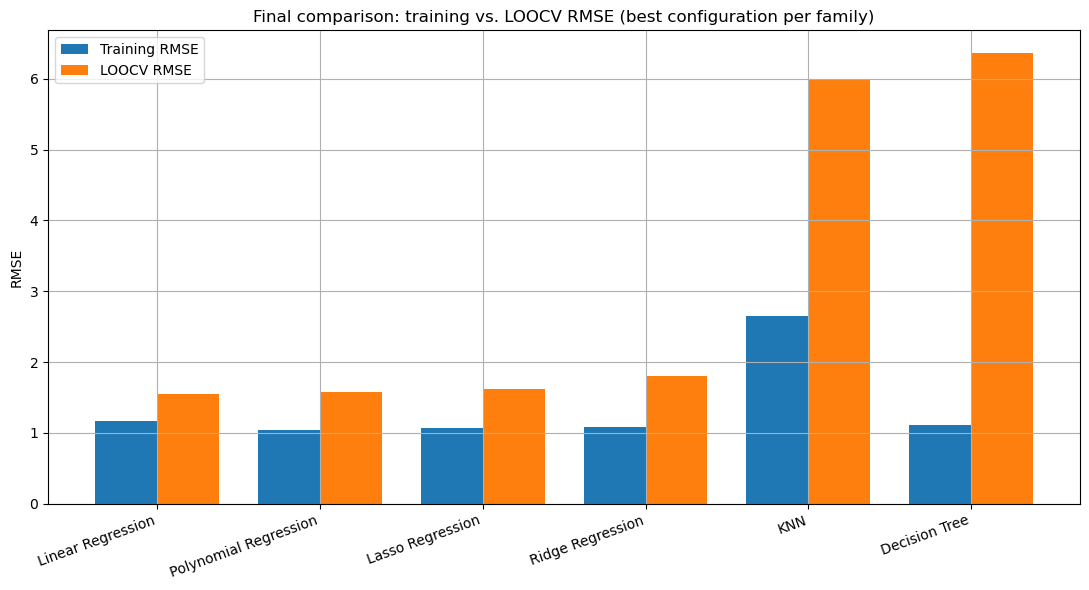

In [24]:
# Comparative plot: training vs LOOCV RMSE
labels = results_D["Model"]
pos = np.arange(len(labels))
w = 0.38

fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(pos - w/2, results_D["Training RMSE"], w, label="Training RMSE", color="tab:blue")
ax.bar(pos + w/2, results_D["LOOCV RMSE"],   w, label="LOOCV RMSE",    color="tab:orange")
ax.set_xticks(pos)
ax.set_xticklabels(labels, rotation=20, ha="right")
ax.set_ylabel("RMSE")
ax.set_title("Final comparison: training vs. LOOCV RMSE (best configuration per family)")
ax.legend()
plt.tight_layout()
plt.show()

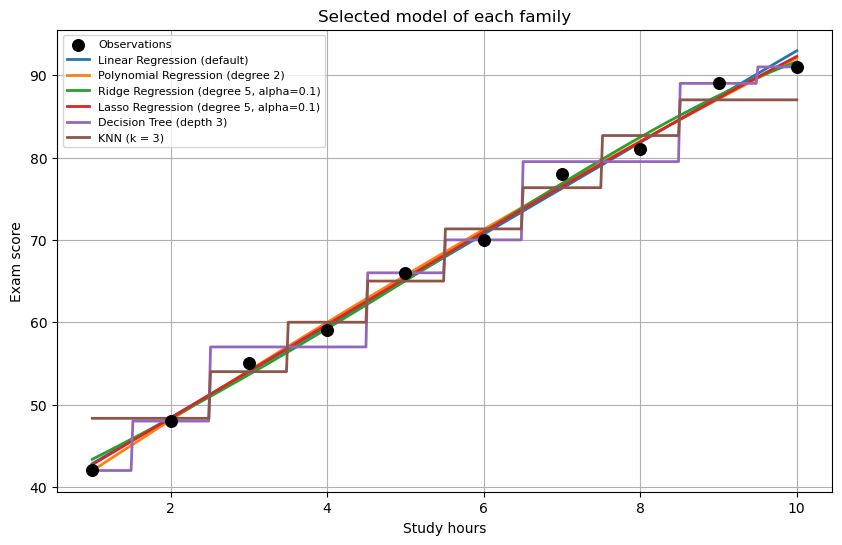

In [25]:
# Fitted curves of the selected models
plt.figure(figsize=(10, 6))
plt.scatter(X, y, color="black", s=70, zorder=5, label="Observations")
for fam, (cfg, est) in families.items():
    est.fit(X, y)
    plt.plot(x_grid, est.predict(x_grid), lw=2, label=f"{fam} ({cfg})")
plt.xlabel("Study hours")
plt.ylabel("Exam score")
plt.title("Selected model of each family")
plt.legend(fontsize=8)
plt.show()

In [27]:
winner = results_D.iloc[0]
print(f"Best generalizing model: {winner['Model']} ({winner['Best configuration']}) "
      f"- LOOCV RMSE = {winner['LOOCV RMSE']:.4f}")

Best generalizing model: Linear Regression (default) - LOOCV RMSE = 1.5486


---
# Conclusion

**Model complexity.** Training error decreases monotonically as the hypothesis space grows (higher polynomial degree, deeper tree), approaching 0 for the degree-9 polynomial when it is numerically well-conditioned (it can interpolate the 10 points). The LOOCV error, however, does not follow this trend: beyond a moderate complexity it stops improving and then degrades sharply, the signature of overfitting. The data are almost linear, so simple models (linear / low-degree polynomial) generalize best, while very flexible models chase noise.

**Feature representation.** The representation determines the hypothesis space. Raw hours give straight lines; polynomial features give smooth curves; trees and KNN give piecewise-constant functions that cannot extrapolate and are coarse with only ten points. Richer representations (x…x⁵) add flexibility, but with so few observations they increase variance and did not improve LOOCV performance over the simple representation.

**Regularization.** Ridge and Lasso reduce the effective complexity of a high-degree polynomial by shrinking (L2) or zeroing (L1) coefficients, and – with scaling inside a Pipeline to avoid data leakage – can substantially reduce the LOOCV error of the degree-5 model relative to the unregularized one. The benefit depends on `alpha`: too small gives no effect, too large underfits.

**Overall.** Generalization is governed by the bias–variance trade-off: choose the model by cross-validated error, not training error; match model complexity to the amount of data and the underlying structure; and use regularization when richer features are needed. Here, a (nearly) linear model, or a regularized polynomial, gives the best predictions on unseen students.